Training samples: 120
Testing samples: 30
Linear Regression trained successfully
Polynomial Regression trained successfully
Ridge Regression trained successfully
                   Model  Train RMSE  Test RMSE  Test R2
0      Linear Regression       4.542      4.217   -0.035
1  Polynomial Regression       1.883      1.861    0.799
2       Ridge Regression       1.826      1.922    0.785


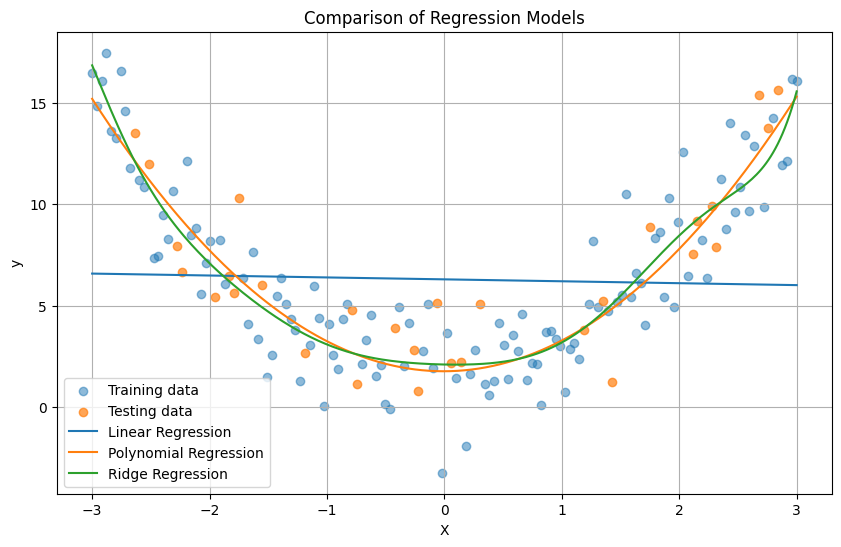

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
# Make results reproducible
np.random.seed(42)

# Generate input values
X = np.linspace(-3, 3, 150).reshape(-1, 1)

# Generate a nonlinear target with random noise
y = 2 + 1.5 * X[:, 0]**2 + np.random.normal(0, 2, 150)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
models = {
    "Linear Regression": make_pipeline(
        PolynomialFeatures(degree=1),
        LinearRegression()
    ),

    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2),
        LinearRegression()
    ),

    "Ridge Regression": make_pipeline(
        PolynomialFeatures(degree=10),
        Ridge(alpha=10)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")
results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train[:, 0],
    y_train,
    alpha=0.5,
    label="Training data"
)

plt.scatter(
    X_test[:, 0],
    y_test,
    alpha=0.7,
    label="Testing data"
)

X_curve = np.linspace(-3, 3, 300).reshape(-1, 1)

for name, model in models.items():
    plt.plot(
        X_curve[:, 0],
        model.predict(X_curve),
        label=name
    )

plt.xlabel("X")
plt.ylabel("y")
plt.title("Comparison of Regression Models")
plt.legend()
plt.grid(True)
plt.show()